#### 0. Data exploration and analysis

In [9]:
from sklearn.datasets import fetch_openml

data = fetch_openml("hls4ml_lhc_jets_hlf", as_frame=True)

X = data.data    
y = data.target   

print(X.shape)              
print(X.columns.tolist())
print(y.value_counts())    
print(X.describe().T) 

(830000, 16)
['zlogz', 'c1_b0_mmdt', 'c1_b1_mmdt', 'c1_b2_mmdt', 'c2_b1_mmdt', 'c2_b2_mmdt', 'd2_b1_mmdt', 'd2_b2_mmdt', 'd2_a1_b1_mmdt', 'd2_a1_b2_mmdt', 'm2_b1_mmdt', 'm2_b2_mmdt', 'n2_b1_mmdt', 'n2_b2_mmdt', 'mass_mmdt', 'multiplicity']
class
t    167851
g    167125
w    167083
z    166875
q    161066
Name: count, dtype: int64
                  count       mean        std           min        25%  \
zlogz          830000.0  -2.865343   0.580389 -4.759511e+00  -3.283773   
c1_b0_mmdt     830000.0   0.433322   0.055448  9.110353e-02   0.419295   
c1_b1_mmdt     830000.0   0.037766   0.029154  7.342856e-05   0.009977   
c1_b2_mmdt     830000.0   0.007995   0.009403  4.472011e-08   0.000337   
c2_b1_mmdt     830000.0   0.045608   0.038657  2.499823e-06   0.015352   
c2_b2_mmdt     830000.0   0.007609   0.012174  1.472518e-10   0.000474   
d2_b1_mmdt     830000.0   1.295784   0.458041  5.866442e-03   0.976546   
d2_b2_mmdt     830000.0   1.083618   0.730066  1.561585e-04   0.485602   
d2

<Axes: >

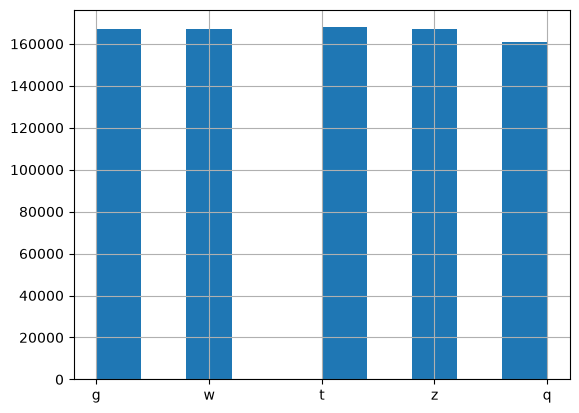

In [10]:
#Lets check if the classes are well balanced
y.hist()

In [5]:
print(X.isna().any().any())
print(y.isna().any())

False
False


The dataset is composed of 830 000 data with 16 features. The dataset is divided betweend 5 classes g,w,t,z and q. \
They are no missing values.
The data are well balanced and doesn't need any specific recalibration on this aspect. \
We already see that the data don't have the same scale and will need some scale adjustments with normalization.

#### 1. Data preparations

In [7]:
from sklearn.model_selection import train_test_split

X_train_val,X_test,y_train_val,y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

X_train,X_val,y_train,y_val = train_test_split(
    X,
    y,
    test_size=0.15/(1-0.15),
    stratify=y,
    random_state=42
)


In [ ]:
import numpy as np

mapping ={name: index for index,name in enumerate(y.unique())}
y.map(mapping).to_numpy(dtype=np.int64)

array([0, 1, 2, ..., 2, 4, 0], shape=(830000,))

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)
y_train = y_train.map(mapping).to_numpy(dtype=np.int64)
y_val = y_val.map(mapping).to_numpy(dtype=np.int64)
y_test = y_test.map(mapping).to_numpy(dtype=np.int64)

#### 2. Model

In [ ]:
from torch import nn

class JetClassifier(nn.Module):
    """MLP : 16 variables en entrée -> logits pour 5 classes."""

    def __init__(
        self,
        n_features=config.N_FEATURES,
        hidden_sizes=(64, 32, 32),
        n_classes=len(config.CLASSES),
        dropout=0.1,
    ):
        super().__init__()
        layers = []
        in_size = n_features
        for hidden_size in hidden_sizes:
            layers += [
                nn.Linear(in_size, hidden_size),  # combinaison pondérée des entrées
                nn.ReLU(),                        # non-linéarité
                nn.Dropout(dropout),              # régularisation (active seulement en mode train)
            ]
            in_size = hidden_size
        # Couche de sortie : 5 logits bruts, SANS softmax (CrossEntropyLoss s'en charge)
        layers.append(nn.Linear(in_size, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)